**Integrantes de Equipo:**

- Jorge Loza Olvera
- Christian Alejandro Dominguez Garcia

# Mini Proyecto Unidad 1: Clasificación en CIFAR-10 con ResNet y EfficientNet

* Pipeline completo de clasificación con CNN (ResNet o EfficientNet) sobre CIFAR-10 (Partes 1 a 5)
* Comparativa técnica de dos arquitecturas CNN con curvas de aprendizaje y métricas (Partes 5 y 6)
*Reporte de diseño (arquitectura, hiperparámetros, estrategia de entrenamiento) (Parte 7)

### Recomendación de entorno

Activen GPU en Colab: **Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU**. ResNet-18 y EfficientNet-B0 a resolución 224×224 son considerablemente más pesados que la CNN pequeña de la práctica anterior; en CPU van a funcionar, pero mucho más lento. Las constantes `TAM_TRAIN`, `TAM_VAL` y `N_EPOCAS` están pensadas para ajustarse según el tiempo y el hardware disponible.


## 0. Configuración inicial

In [1]:
!pip install -q torchmetrics


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 50.0 MB/s eta 0:00:00


In [2]:
import time

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.models as models
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt
import pandas as pd

from torchmetrics.classification import (
    MulticlassAccuracy,
    MulticlassPrecision,
    MulticlassRecall,
    MulticlassF1Score,
    MulticlassConfusionMatrix,
)

torch.manual_seed(42)

DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", DISPOSITIVO)

Dispositivo: cuda


---
## 1. Datos: CIFAR-10 a 224x224

ResNet y EfficientNet, tal como se definen en `torchvision.models`, esperan entradas de 224x224 pixeles (el tamano estandar de ImageNet en el que se disenaron y evaluaron originalmente). Redimensionamos CIFAR-10 (32x32 nativo) a ese tamaño.


In [ ]:
MEDIA_IMAGENET = (0.485, 0.456, 0.406)
STD_IMAGENET = (0.229, 0.224, 0.225)

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEDIA_IMAGENET, STD_IMAGENET),
])
# COMPLETAR CARGAR IMAGENES DE ENTRENAMIENTO Y PRUEBA Y GENERAR UN SUBCONJUNTO
trainset_completo = torchvision.datasets.CIFAR10(root="./data", download=True, train=True, transform=transform)
testset = torchvision.datasets.CIFAR10(root="./data", download=True, train=False, transform=transform)
train_subset, val_subset = torch.utils.data.random_split(trainset_completo, [40000, 10000])


nombres_clases = trainset_completo.classes
print("Clases:", nombres_clases)
print("Tamano del set de entrenamiento completo:", len(trainset_completo))
print("Tamano del set de prueba:", len(testset))


100%|██████████| 170M/170M [33:37<00:00, 84.5kB/s]


Clases: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Tamano del set de entrenamiento completo: 50000
Tamano del set de prueba: 10000


### 1.1 Subconjuntos de trabajo



Entrenamiento: 40000 imagenes  |  Validacion: 10000  |  Prueba: 10000


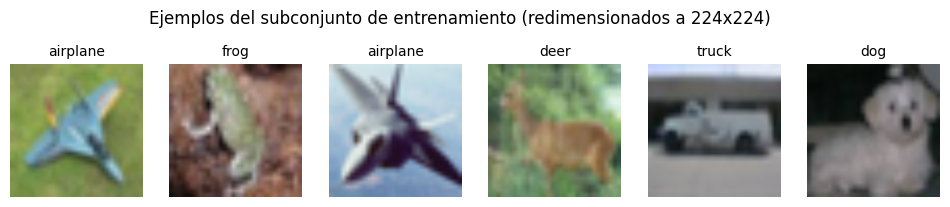

In [ ]:
BATCH_SIZE = 32
train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(testset, batch_size=64, shuffle=False, num_workers=2)

print(f"Entrenamiento: {len(train_subset)} imagenes  |  Validacion: {len(val_subset)}  |  Prueba: {len(testset)}")


def desnormalizar(img_tensor):
    """Invierte la normalizacion para poder visualizar la imagen."""
    media = torch.tensor(MEDIA_IMAGENET).view(3, 1, 1)
    std = torch.tensor(STD_IMAGENET).view(3, 1, 1)
    return (img_tensor * std + media).clamp(0, 1)


imagenes, etiquetas = next(iter(train_loader))
fig, axs = plt.subplots(1, 6, figsize=(12, 2.5))
for i, ax in enumerate(axs):
    ax.imshow(desnormalizar(imagenes[i]).permute(1, 2, 0))
    ax.set_title(nombres_clases[etiquetas[i]], fontsize=10)
    ax.axis("off")
plt.suptitle("Ejemplos del subconjunto de entrenamiento (redimensionados a 224x224)")
plt.show()


---
## 2. Construir ResNet-18 y EfficientNet-B0

Tomamos las arquitecturas de `torchvision.models` con pesos preentrenados en ImageNet (`weights="DEFAULT"`) y adaptamos unicamente la ultima capa para que clasifique entre las 10 clases de CIFAR-10 en vez de las 1000 de ImageNet — el resto de la arquitectura, y sus pesos preentrenados, se conservan exactamente como en 1.3.

Ver : https://docs.pytorch.org/vision/main/models.html


Ejemplo: https://docs.pytorch.org/vision/main/models/generated/torchvision.models.resnet18.html


In [4]:
# COMPLETAR construir_efficientnet(n_clases=10)
efficientnet_model = torchvision.models.efficientnet_b0(weights="DEFAULT")
efficientnet_model.classifier[1] = torch.nn.Linear(efficientnet_model.classifier[1].in_features, out_features=10)
efficientnet_model.to(DISPOSITIVO)
total_params = sum(p.numel() for p in efficientnet_model.parameters())
print(f"Número total de parámetros EFFICIENTNET: {total_params:,}")
#COMPLETAR  construir_resnet18(n_clases=10)
resnet_model = torchvision.models.resnet18(weights="DEFAULT")
resnet_model.fc = torch.nn.Linear(resnet_model.fc.in_features, out_features=10)
resnet_model.to(DISPOSITIVO)
total_params = sum(p.numel() for p in resnet_model.parameters())
print(f"Número total de parámetros RESNET: {total_params:,}")



Número total de parámetros EFFICIENTNET: 4,020,358
Número total de parámetros RESNET: 11,181,642


In [ ]:
#Qué flojera volver a descargar esto
!zip -r cifar_data.zip ./data

  adding: data/ (stored 0%)
  adding: data/cifar-10-batches-py/ (stored 0%)
  adding: data/cifar-10-batches-py/data_batch_1 (deflated 9%)
  adding: data/cifar-10-batches-py/batches.meta (deflated 12%)
  adding: data/cifar-10-batches-py/data_batch_3 (deflated 8%)
  adding: data/cifar-10-batches-py/test_batch (deflated 8%)
  adding: data/cifar-10-batches-py/readme.html (stored 0%)
  adding: data/cifar-10-batches-py/data_batch_2 (deflated 8%)
  adding: data/cifar-10-batches-py/data_batch_4 (deflated 8%)
  adding: data/cifar-10-batches-py/data_batch_5 (deflated 8%)
  adding: data/cifar-10-python.tar.gz (deflated 0%)


---
## 3. Metricas con TorchMetrics

Mismo patron que en la Practica 4 original: `update()` por lote, `compute()` al final de la epoca, `reset()` antes de la siguiente. Usamos `average="macro"` (promedio simple entre las 10 clases)

ver: https://meta-pytorch.org/torcheval/main/torcheval.metrics.html

Ejemplo :  
"accuracy": MulticlassAccuracy(num_classes=n_clases, average="macro").to(DISPOSITIVO),



In [ ]:
def crear_metricas(n_clases=10):
    return {
        "accuracy": MulticlassAccuracy(num_classes=n_clases, average="macro").to(DISPOSITIVO),
        "precision": MulticlassPrecision(num_classes=n_clases, average="macro").to(DISPOSITIVO),
        "recall": MulticlassRecall(num_classes=n_clases, average="macro").to(DISPOSITIVO),
        "f1": MulticlassF1Score(num_classes=n_clases, average="macro").to(DISPOSITIVO),
    }


def correr_epoca(modelo, loader, perdida_fn, metricas, optimizador=None):
    """
    Corre una epoca completa. Si optimizador no es None, entrena (backward + step);
    si es None, solo evalua (torch.no_grad()).
    """
    modo_entrenamiento = optimizador is not None
    modelo.train() if modo_entrenamiento else modelo.eval()

    for m in metricas.values():
        m.reset()

    perdida_acumulada, n_lotes = 0.0, 0
    contexto = torch.enable_grad() if modo_entrenamiento else torch.no_grad()

    with contexto:
        for imagenes, etiquetas in loader:
            imagenes, etiquetas = imagenes.to(DISPOSITIVO), etiquetas.to(DISPOSITIVO)

            if modo_entrenamiento:
                optimizador.zero_grad()

            salida = modelo(imagenes)
            perdida = perdida_fn(salida, etiquetas)

            if modo_entrenamiento:
                perdida.backward()
                optimizador.step()

            perdida_acumulada += perdida.item()
            n_lotes += 1

            preds = salida.argmax(dim=1)
            for m in metricas.values():
                m.update(preds, etiquetas)

    resultados = {nombre: m.compute().item() for nombre, m in metricas.items()}
    resultados["loss"] = perdida_acumulada / n_lotes
    return resultados


---
## 4. Entrenar ambos modelos en igualdad de condiciones

Para que la comparacion sea tecnicamente valida, ambos modelos usan **los mismos datos, el mismo numero de epocas, el mismo optimizador y el mismo learning rate**. Documentamos estos hiperparametros aqui porque los van a necesitar tal cual para el reporte de diseno (Parte 7).


In [ ]:
#hiperparámetros para ambos
loss_function = torch.nn.CrossEntropyLoss()
epochs = 5
metricas = crear_metricas()

**EfficientNet entrenamiento**

In [ ]:
#esto para reiniciar el modelo cada vez que se vuelva a correr el notebook
efficientnet_model = torchvision.models.efficientnet_b0(weights="DEFAULT")
efficientnet_model.classifier[1] = torch.nn.Linear(efficientnet_model.classifier[1].in_features, out_features=10)
efficientnet_model.to(DISPOSITIVO)

optimizer = torch.optim.Adam(efficientnet_model.parameters(),lr=0.0001)


resultados_effiNet_list_train = []
resultados_effiNet_list_val = []
tiempos_effiNet = []
epochs_list = []

for epoch in range(epochs):
  t0 = time.time()

  resultados_effiNet_train = correr_epoca(modelo=efficientnet_model,
                                    loader=train_loader,
                                    perdida_fn= loss_function,
                                    metricas=metricas,
                                    optimizador=optimizer)

  resultados_effiNet_list_train.append(resultados_effiNet_train)

  resultados_effiNet_val = correr_epoca(modelo=efficientnet_model,
                                    loader=val_loader,
                                    perdida_fn= loss_function,
                                    metricas=metricas)

  resultados_effiNet_list_val.append(resultados_effiNet_val)
  epochs_list.append(epoch)
  tiempos_effiNet.append(time.time() - t0)

**ResNet entrenamiento**

In [ ]:
resnet_model = torchvision.models.resnet18(weights="DEFAULT")
resnet_model.fc = torch.nn.Linear(resnet_model.fc.in_features, out_features=10)
resnet_model.to(DISPOSITIVO)

optimizer_resnet = torch.optim.Adam(resnet_model.parameters(), lr=0.0001)

resultados_resnet_list_train = []
resultados_resnet_list_val = []
tiempos_resnet = []

for epoch in range(epochs):
    t0 = time.time()

    resultados_train = correr_epoca(modelo=resnet_model,
                                    loader=train_loader,
                                    perdida_fn=loss_function,
                                    metricas=metricas,
                                    optimizador=optimizer_resnet)
    resultados_resnet_list_train.append(resultados_train)

    resultados_val = correr_epoca(modelo=resnet_model,
                                  loader=val_loader,
                                  perdida_fn=loss_function,
                                  metricas=metricas)
    resultados_resnet_list_val.append(resultados_val)
    tiempos_resnet.append(time.time() - t0)

---
## 5. Curvas de aprendizaje: ResNet-18 vs. EfficientNet-B0

Mismo diagnostico que en 1.4: comparen el gap train/val de cada modelo, y ahora tambien comparenlos *entre si* — ¿cual generaliza mejor con el mismo presupuesto de datos y epocas?


**Gráficos de EfficientNet**

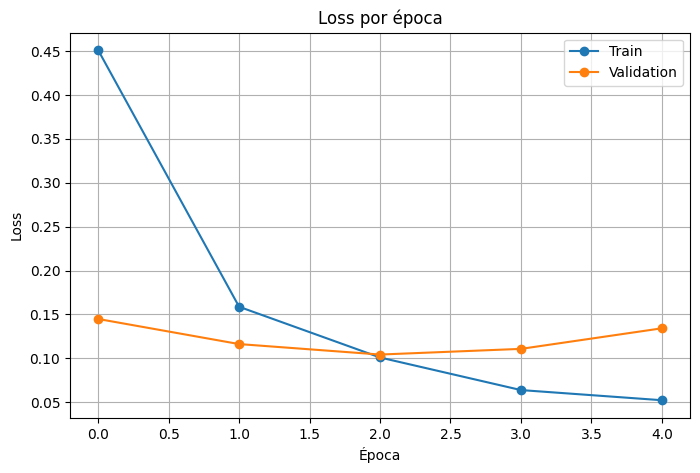

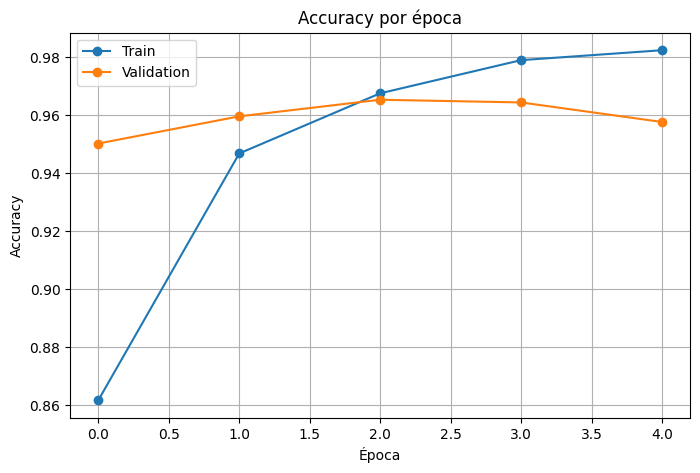

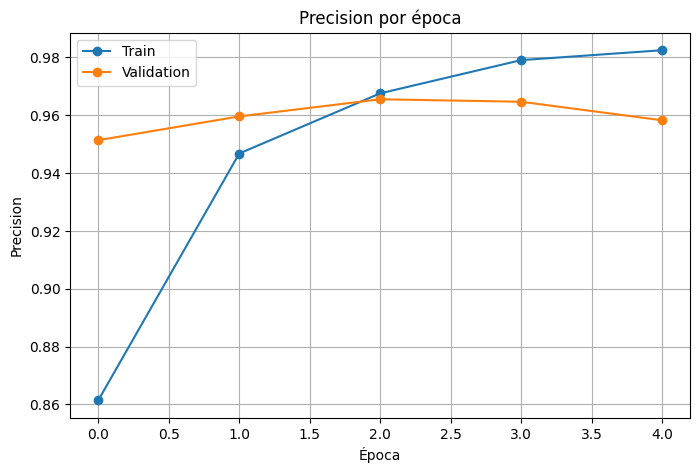

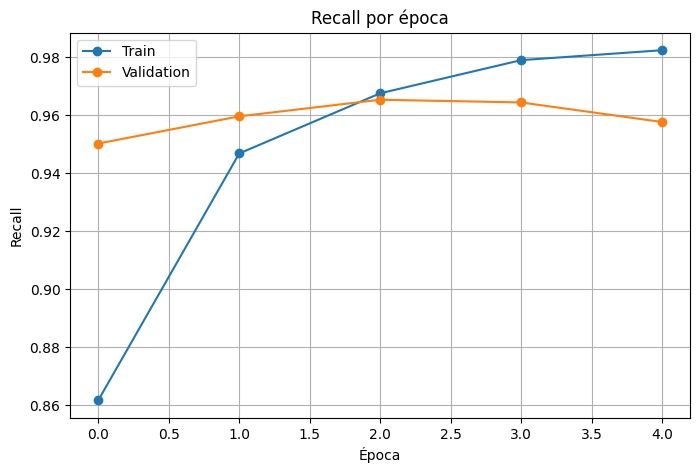

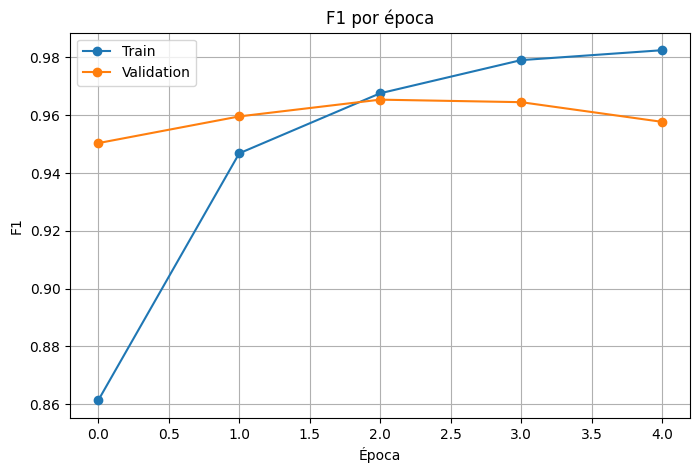

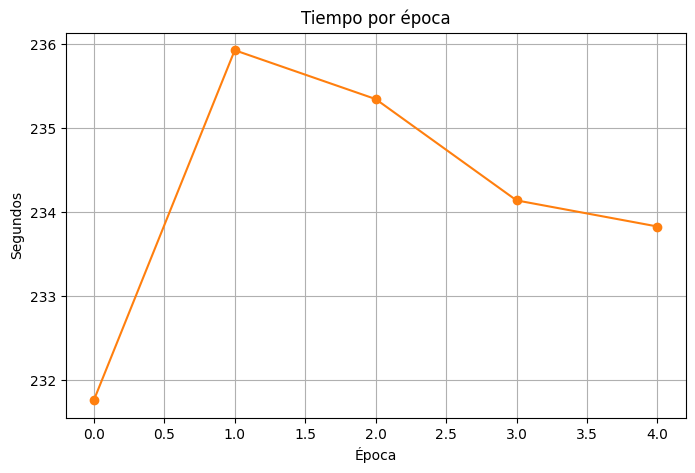

In [ ]:
#acá va el gráfico
metricas_graficar = ["loss", "accuracy", "precision", "recall", "f1"]

for metrica in metricas_graficar:

    train_valores = [resultado[metrica] for resultado in resultados_effiNet_list_train]
    val_valores = [resultado[metrica] for resultado in resultados_effiNet_list_val]

    plt.figure(figsize=(8, 5))
    plt.plot(epochs_list, train_valores, marker="o", label="Train")
    plt.plot(epochs_list, val_valores, marker="o", label="Validation")
    plt.xlabel("Época")
    plt.ylabel(metrica.capitalize())
    plt.title(f"{metrica.capitalize()} por época")
    plt.legend()
    plt.grid()
    plt.show()

#gráfica del tiempo
plt.figure(figsize=(8, 5))
plt.plot(epochs_list, tiempos_effiNet, marker="o", color="tab:orange")
plt.xlabel("Época")
plt.ylabel("Segundos")
plt.title("Tiempo por época")
plt.grid()
plt.show()

**Gráficos de ResNet**

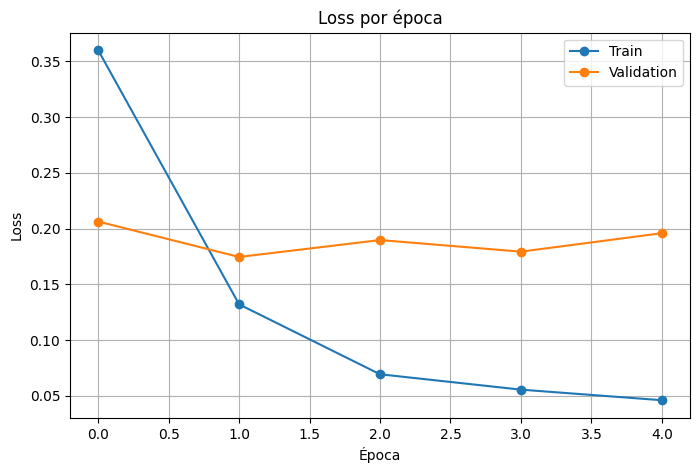

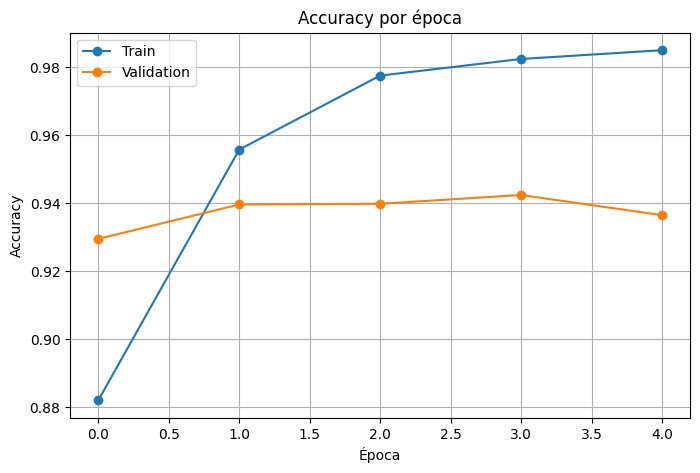

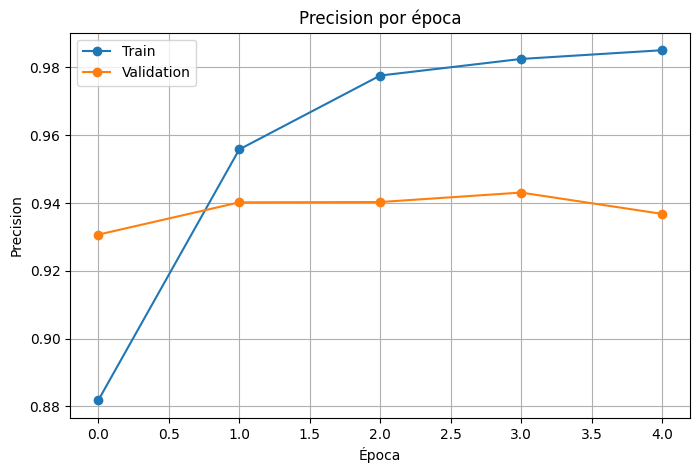

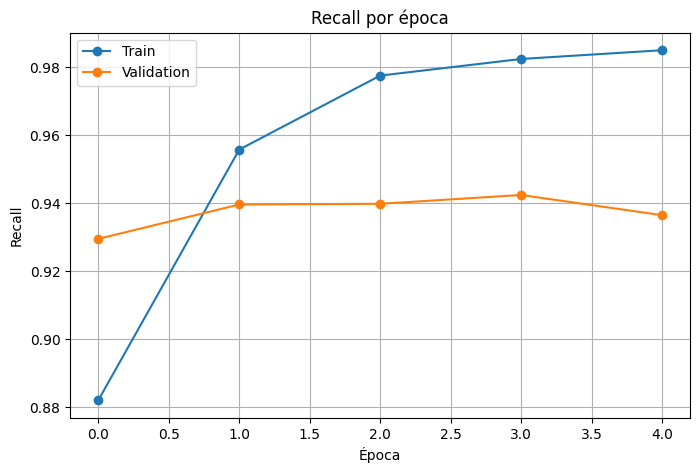

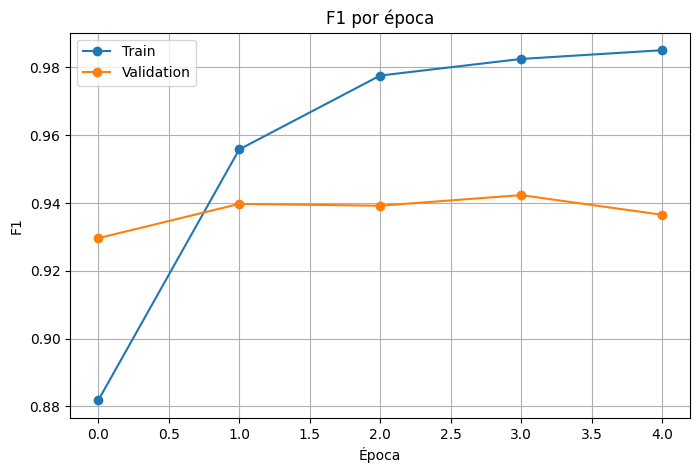

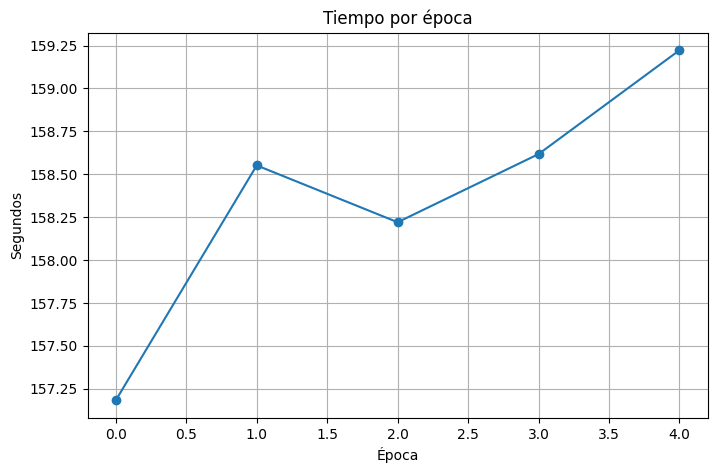

In [ ]:
for metrica in metricas_graficar:

    train_valores = [resultado[metrica] for resultado in resultados_resnet_list_train]
    val_valores = [resultado[metrica] for resultado in resultados_resnet_list_val]

    plt.figure(figsize=(8, 5))
    plt.plot(epochs_list, train_valores, marker="o", label="Train")
    plt.plot(epochs_list, val_valores, marker="o", label="Validation")
    plt.xlabel("Época")
    plt.ylabel(metrica.capitalize())
    plt.title(f"{metrica.capitalize()} por época")
    plt.legend()
    plt.grid()
    plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs_list, tiempos_resnet, marker="o", color="tab:blue")
plt.xlabel("Época")
plt.ylabel("Segundos")
plt.title("Tiempo por época")
plt.grid()
plt.show()

**Comparación**

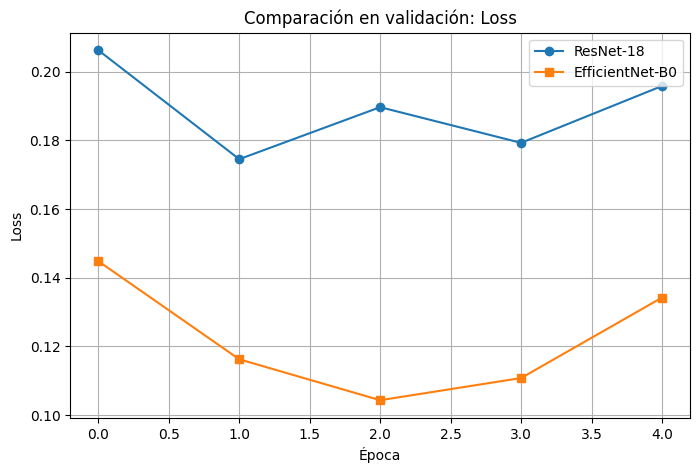

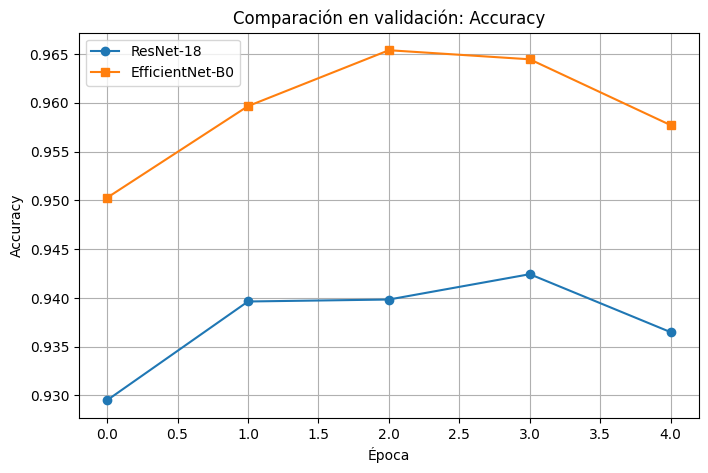

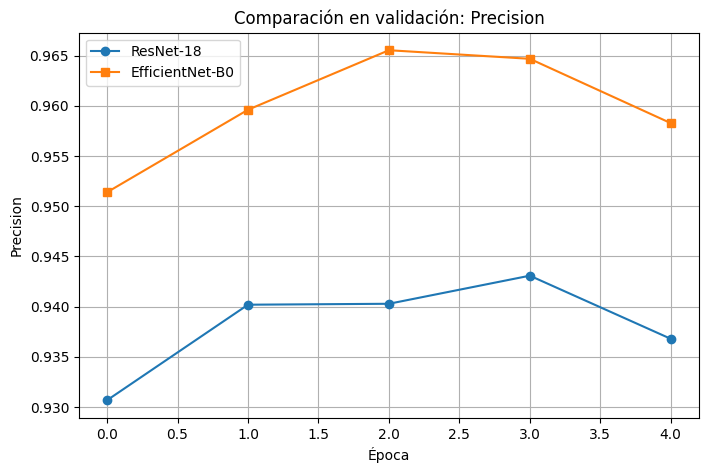

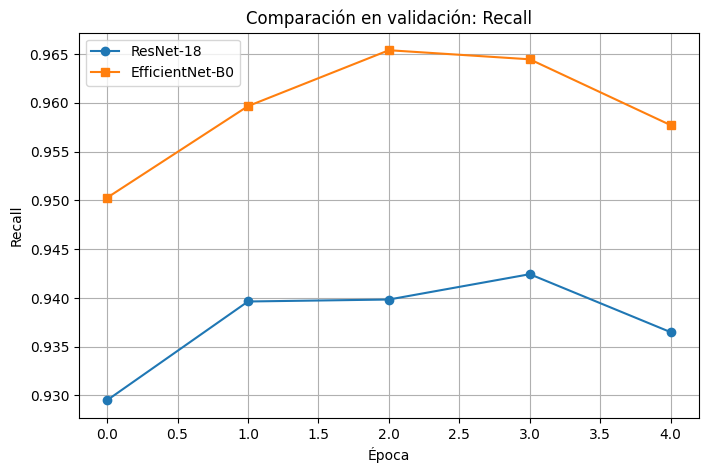

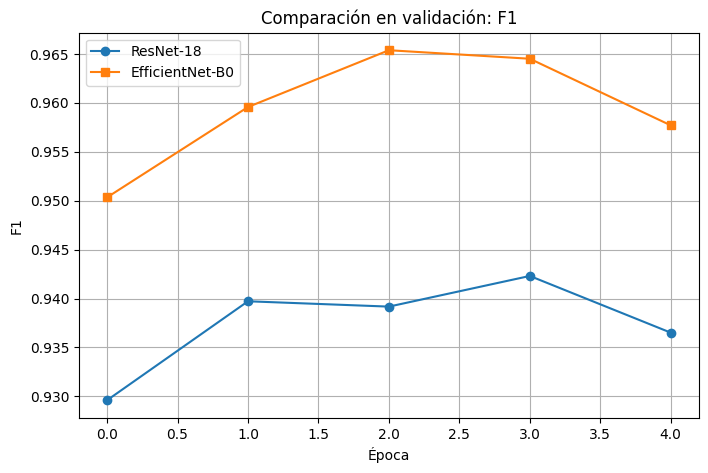

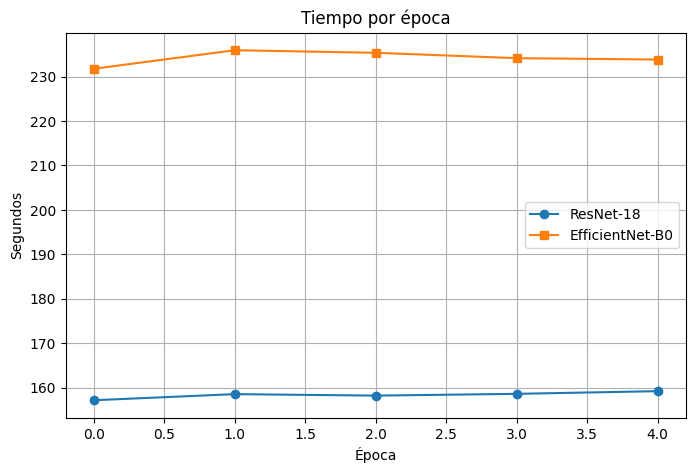

In [ ]:
for metrica in metricas_graficar:
    plt.figure(figsize=(8, 5))
    plt.plot(epochs_list, [r[metrica] for r in resultados_resnet_list_val], marker="o", label="ResNet-18")
    plt.plot(epochs_list, [r[metrica] for r in resultados_effiNet_list_val], marker="s", label="EfficientNet-B0")
    plt.xlabel("Época")
    plt.ylabel(metrica.capitalize())
    plt.title(f"Comparación en validación: {metrica.capitalize()}")
    plt.legend()
    plt.grid()
    plt.show()

#gráfica del tiempo
plt.figure(figsize=(8, 5))
plt.plot(epochs_list, tiempos_resnet, marker="o", label="ResNet-18")
plt.plot(epochs_list, tiempos_effiNet, marker="s", label="EfficientNet-B0")
plt.xlabel("Época")
plt.ylabel("Segundos")
plt.title("Tiempo por época")
plt.legend()
plt.grid()
plt.show()

---
## 6. Reporte final sobre el set de prueba

Evaluamos ambos modelos sobre las 10,000 imagenes de prueba de CIFAR-10


In [ ]:
def evaluar_en_prueba(modelo, nombre_modelo):
    metrica_acc = MulticlassAccuracy(num_classes=10, average="macro").to(DISPOSITIVO)
    metrica_prec = MulticlassPrecision(num_classes=10, average="macro").to(DISPOSITIVO)
    metrica_rec = MulticlassRecall(num_classes=10, average="macro").to(DISPOSITIVO)
    metrica_f1 = MulticlassF1Score(num_classes=10, average="macro").to(DISPOSITIVO)
    metrica_matriz = MulticlassConfusionMatrix(num_classes=10).to(DISPOSITIVO)

    modelo.eval()
    with torch.no_grad():
        for imagenes, etiquetas in test_loader:
            imagenes, etiquetas = imagenes.to(DISPOSITIVO), etiquetas.to(DISPOSITIVO)
            preds = modelo(imagenes).argmax(dim=1)
            for m in [metrica_acc, metrica_prec, metrica_rec, metrica_f1, metrica_matriz]:
                m.update(preds, etiquetas)

    resumen = {
        "modelo": nombre_modelo,
        "accuracy": metrica_acc.compute().item(),
        "precision": metrica_prec.compute().item(),
        "recall": metrica_rec.compute().item(),
        "f1": metrica_f1.compute().item(),
    }
    return resumen, metrica_matriz.compute().cpu().numpy()


resumen_resnet, matriz_resnet = evaluar_en_prueba(resnet_model, "ResNet-18")
resumen_efficientnet, matriz_efficientnet = evaluar_en_prueba(efficientnet_model, "EfficientNet-B0")

df_comparativa = pd.DataFrame([resumen_resnet, resumen_efficientnet]).round(3)
df_comparativa


,modelo,accuracy,precision,recall,f1
0,ResNet-18,0.933,0.934,0.933,0.933
1,EfficientNet-B0,0.956,0.957,0.956,0.956


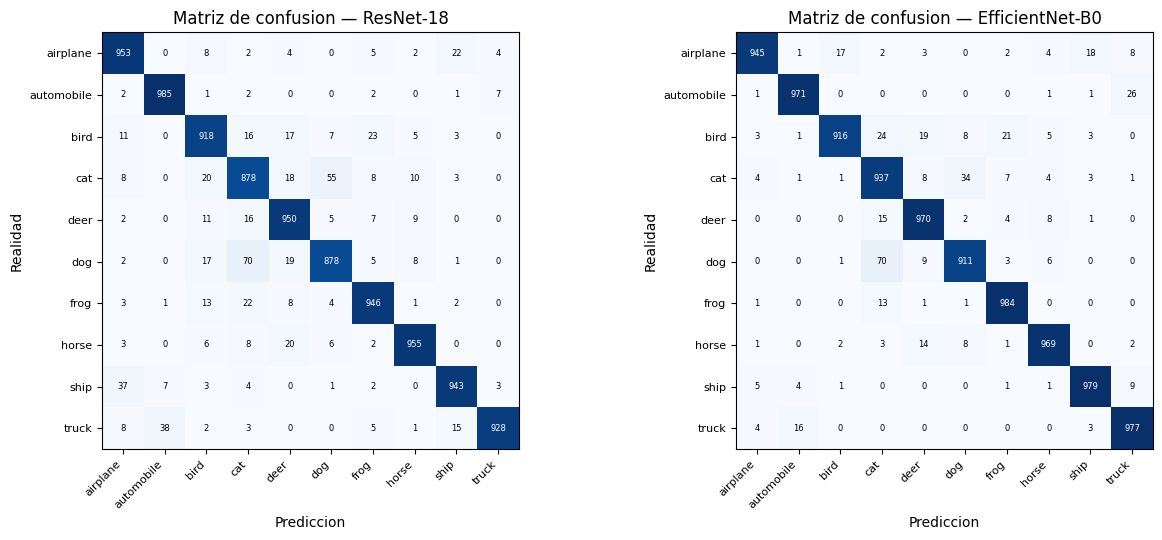

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5.5))

for ax, matriz, nombre in [(axs[0], matriz_resnet, "ResNet-18"), (axs[1], matriz_efficientnet, "EfficientNet-B0")]:
    im = ax.imshow(matriz, cmap="Blues")
    ax.set_xticks(range(10)); ax.set_xticklabels(nombres_clases, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(10)); ax.set_yticklabels(nombres_clases, fontsize=8)
    ax.set_xlabel("Prediccion"); ax.set_ylabel("Realidad")
    ax.set_title(f"Matriz de confusion — {nombre}")
    for i in range(10):
        for j in range(10):
            color = "white" if matriz[i, j] > matriz.max() / 2 else "black"
            ax.text(j, i, str(int(matriz[i, j])), ha="center", va="center", color=color, fontsize=6)

plt.tight_layout()
plt.show()


---
## 7. Reporte de diseño (completar en equipo)

Esta seccion es, literalmente, la evidencia **"Reporte de diseño"** del temario de la Unidad 1. Respondan cada punto con base en lo que observaron arriba — pueden editar esta celda de markdown directamente o copiar las respuestas a un documento aparte.

**1. Arquitectura y justificación**
> *(¿Cuál de las dos arquitecturas usarían si solo pudieran quedarse con una para este problema? Justifiquen con los números de la Parte 6, no solo con la teoría de 1.3.)*

**Respuesta:** Nos quedaríamos con la EfficientNet si se trata de desempeño, ya que, como se observa en las gráficas y la matriz de comparación, EfficientNet tuvo un mejor resultado en general respecto a ResNet. También es importante señalar que requiere más poder computacional y tarda más en promedio por época, pero es un costo considerable a aceptar por precisión

**2. Hiperparámetros usados**
> Learning rate: `__0.0001___`  ·  Optimizador: `__Adam___`  ·  Épocas: `___5__`  ·  Batch size: `__32___`  ·  Tamaño del subconjunto de entrenamiento: `___4000__`  ·  Pesos iniciales: preentrenados (ImageNet)

**3. Estrategia de entrenamiento**
> *(¿Entrenaron con GPU o CPU? ¿Cuánto tardó cada época de cada modelo? Si tuvieran que reentrenar con más tiempo disponible, ¿qué cambiarían primero: más datos, más épocas, u otro hiperparámetro?)*

**Respuesta:** Entrenamos con el GPU T4 de collab, en promedio ResNet duraba alrededor de 160s o segundos menos en cada época, mientras que EfficientNet duraba 230s o unos segundos más. Si hubiera más tiempo disponible, por como se comportan las gráficas podríamos ver que agregar más épocas no crearía un mejor modelo (de hecho se aplana o baja un poco las métricas y tal vez pueda llegar a un overfitting), por lo que sería mejor agregar más datos para una mejor generalización del problema y tal vez modificar un hiperparámetro como learning rate para observar como afecta el entrenamiento

**4. Diagnóstico de las curvas (conexión con 1.4)**
> *(¿Alguno de los dos modelos mostró señales de overfitting según el checklist de la diapositiva 21? ¿Cuál generalizó mejor — menor gap train/val, no necesariamente mayor accuracy?)*

**Respuesta:** Sí, tanto ResNet como EfficientNet mostraron señales leves de sobreajuste en los valores de pérdida y accuracy, mostrando valores más altos durante el entrenamiento que en el conjutno de validación. El valor GAP para EfficientNet fue de 0.09, mientras que el de ResNet fue de 0.15. A pesar de esto, EfficientNet presenta también un mayor puntaje general en las métricas propuestas además de una mejor generalización, ResNet presentó un 0.93 en accuracy, mientras que EfficientNet 0.95.

**5. Capacidad vs. eficiencia (conexión con 1.3)**
> *(Con el número de parámetros de la Parte 2 y el accuracy final de la Parte 6: ¿cuál modelo ofrece mejor relación desempeño/costo computacional en este experimento?)*

**Respuesta: ** Dados los parámetros definidos en la sección número 2 del cuaderno:

Número total de parámetros EFFICIENTNET: 4,020,358

Número total de parámetros RESNET: 11,181,642

Y las métricas obtenidas en test bajo los mismos datos de entrenamiento y validación, así como hiperparámetros:

| Modelo | Accuracy | Precision | Recall | F1 |
| :--- | :---: | :---: | :---: | :---: |
| ResNet-18 | 0.933 | 0.934 | 0.933 | 0.933 |
| EfficientNet-B0 | 0.956 | 0.957 | 0.956 | 0.956 |

EfficientNet se posiciona como el mejor modelo en términos de eficiencia/precisión, debido a que contiene una menor cantidad de parámetros entrenables y obtuvo mejores resultados en todas las métricas implementadas (Accuracy, Precision, Recall, F1). Potr otro lado, ResNet cuenta con casi tres veces los parámetros de EfficientNet y obtiene puntuaciones menores en las métricas antes mencionadas.


**6. Errores más frecuentes**
> *(Con las matrices de confusión de la Parte 6: ¿qué par de clases confunde más cada modelo? ¿Tiene sentido esa confusión dado lo que representan esas clases?)*

EfficientNet: Las clases con menor cantidad de Verdaderos Positivos con la clase Dog y Bird. Respecto a la primera clase mencionada, tiene sentido que el modelo tenga dificultades para su clasificación debido a la similitud con la clase Cat, que es la clase más frecuente en Falsos Negativos, con un valor de 70 observaciones de perros que fueron predichos como gatos. La segunda clase con menor cantidad de Verdaderos Positivos es la de Bird, siendo esta confundida por el modelo de forma uniforme con las clases de Cat, Deer y Frog, nuestra hipótesis es que el moedelo puede confundirlos debido a los rasgos finos o tamaño de las categorías.

ResNet: Las clases con menor cantidad de Verdaderos Positivos fueron Dog, Cat y Bird, donde Cat y Dog cuentan con el mismo valor de 878 de VP. De manera similar que son EfficientNet, el modelo tiende a confundir las clases de Cat y Dog entre sí, teniendo 70 FN la clase Dog respecto a Gato y 55 viceversa. La clase de Cat suele ser confundida con Deer, con un total de 18 FN respecto a esa clase. Al igual que EfficientNet, la clase Bird suele ser confundida de manera uniforme con las clases Cat, Deer y Frog.

Podemos observar que las discrepancias entre clases están presentes en ambos modelos, como es el caso de la confusión entre clases Cat, Dog y Bird. Nuestras hipótesis sobre las clases Cat y Dog son, además de la similitud morfológica o el pelaje, es que las fotografías de ambas clases suelen contener también el mismo fondo o escenarios, por lo que el modelo puede tomar en cuenta estas características al momento de clasiicar, logrando tener un peso comparable al de el objeto en sí.

---
## 8. Cierre y entregables del mini proyecto

### Checklist de entrega

- [ ] Notebook ejecutado de principio a fin, sin errores, con las celdas de ambos modelos corridas.
- [ ] Tabla comparativa final (Parte 6) con accuracy, precision, recall y F1 de ambos modelos.
- [ ] Graficas de curvas de entrenamiento (Parte 5) y matrices de confusion (Parte 6).
- [ ] Reporte de diseno (Parte 7) completado por el equipo.
- [ ] Hiperparametros documentados tal como quedaron configurados al momento de generar los resultados finales.


### Recursos citados

- Katanforoosh, K., & Ng, A. *Stanford CS230* — Section 8, "Advanced Evaluation Metrics". [cs230.stanford.edu/section/8](https://cs230.stanford.edu/section/8)
- TorchMetrics documentation — *Classification: Accuracy*. [torchmetrics.readthedocs.io/en/v0.9.1/classification/accuracy.html](https://torchmetrics.readthedocs.io/en/v0.9.1/classification/accuracy.html)
- Ultralytics. *Consejos y buenas practicas para entrenar modelos*. [docs.ultralytics.com/es/guides/model-training-tips](https://docs.ultralytics.com/es/guides/model-training-tips)
- He, K., Zhang, X., Ren, S., & Sun, J. (2015). Deep residual learning for image recognition. arXiv:1512.03385.
- Tan, M., & Le, Q. (2019). EfficientNet: Rethinking model scaling for convolutional neural networks. ICML 2019.
- Ayyadevara, K., & Reddy, Y. (2024). *Modern Computer Vision with PyTorch*. Packt Publishing.
